# Exploration : nébulosité observée aux lieux cibles

Table `cloud_hourly` (stations NOAA GHCNh) : une ligne par lieu et par heure UTC, couverture en octas
(0 = ciel dégagé, 8 = couvert). Mêmes prérequis que le notebook 01 (`data/clean` récupéré depuis la branche `clean-data`).

Remarque : la nuit noire n'est pas encore calculée ; les parts ci-dessous portent sur **toutes les heures observées**,
de jour comme de nuit. Elles seront affinées aux heures de nuit noire quand la table astronomique existera.

In [1]:
import matplotlib.pyplot as plt

from auroracast.data import load

COLORS = {"tromso": "#2a78d6", "kiruna": "#eb6834", "rovaniemi": "#1baf7a"}
NAMES = {"tromso": "Tromsø", "kiruna": "Kiruna", "rovaniemi": "Rovaniemi"}
MUTED, INK = "#52514e", "#0b0b0b"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

locations = load("locations")
clouds = load("cloud_hourly")
locations

,location,lat,lon,station_id,station_name,station_distance_km
0,tromso,69.6496,18.9560,NOM00001026,TROMSO,0.9
1,kiruna,67.8558,20.2253,SWI0000ESNQ,"KIRUNA (aéroport, ESNQ)",6.0
2,rovaniemi,66.5039,25.7294,FIM00002847,ROVANIEMI RAUTATIEASEMA,0.7


## 1. Part de ciel dégagé par mois

Part des observations à 0, 1 ou 2 octas, de 2010 à 2026, mois par mois. La saison des aurores va de septembre à mars.

**Point à vérifier avant de conclure** : une couverture de 0 octa peut aussi venir d'une station automatique qui ne détecte pas de nuage (code « NCD », capteur aveugle aux nuages élevés) ou d'une observation de nuit difficile. Tromsø plus dégagé en janvier qu'en mars est surprenant pour une station côtière : à confirmer avec les codes de type de rapport (`*_Report_Type`) et la table astronomique (nuit polaire).

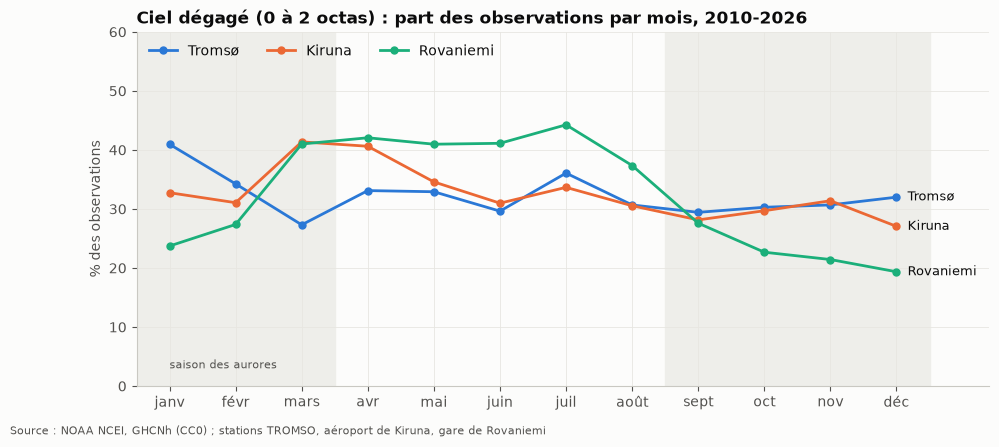

location,Kiruna,Rovaniemi,Tromsø
month,,,
janv,32.7,23.7,41.0
févr,31.1,27.4,34.2
mars,41.4,41.0,27.3
avr,40.6,42.1,33.1
mai,34.6,41.0,32.9
juin,31.0,41.1,29.6
juil,33.7,44.3,36.1
août,30.5,37.4,30.7
sept,28.1,27.6,29.4


In [2]:
obs = clouds[clouds["oktas"].notna()].copy()
obs["month"] = obs["time"].dt.month
obs["clear"] = obs["oktas"] <= 2
clear = obs.pivot_table(index="month", columns="location", values="clear", aggfunc="mean") * 100

months = ["janv", "févr", "mars", "avr", "mai", "juin", "juil", "août", "sept", "oct", "nov", "déc"]
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axvspan(0.5, 3.5, color="#eeeeea", zorder=0)
ax.axvspan(8.5, 12.5, color="#eeeeea", zorder=0)
ax.text(1, 3, "saison des aurores", fontsize=8, color=MUTED)
for loc in ["tromso", "kiruna", "rovaniemi"]:
    ax.plot(clear.index, clear[loc], color=COLORS[loc], linewidth=2, marker="o", markersize=5,
            label=NAMES[loc])
    ax.annotate(NAMES[loc], (12, clear.loc[12, loc]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_xticks(range(1, 13), months)
ax.set_xlim(0.5, 13.4)
ax.set_ylim(0, max(60, clear.max().max() + 5))
ax.set_ylabel("% des observations")
ax.set_title("Ciel dégagé (0 à 2 octas) : part des observations par mois, 2010-2026")
ax.legend(frameon=False, loc="upper left", ncols=3)
fig.text(0.01, 0.005, "Source : NOAA NCEI, GHCNh (CC0) ; stations TROMSO, aéroport de Kiruna, gare de Rovaniemi",
         fontsize=8, color=MUTED)
plt.show()
clear.round(1).rename(index=dict(enumerate(months, 1)), columns=NAMES)

## 2. Complétude des observations par année

Part des heures où une observation de nuages existe. Tromsø n'observe que toutes les 3 heures (environ 33 % au mieux).

In [3]:
share = (clouds.assign(year=clouds["time"].dt.year, has=clouds["oktas"].notna())
               .pivot_table(index="year", columns="location", values="has", aggfunc="mean") * 100)
share.round(1).rename(columns=NAMES)

location,Kiruna,Rovaniemi,Tromsø
year,,,
2010,87.0,65.1,31.6
2011,85.8,64.1,30.1
2012,86.5,54.5,31.2
2013,80.9,55.1,31.6
2014,81.8,60.3,32.9
2015,86.9,68.3,33.2
2016,85.8,89.3,32.9
2017,86.0,99.5,33.0
2018,85.5,96.2,32.9
